# ISO 21448: Safety of the Intended Functionality (SOTIF)

**Module 04 · SOTIF (ISO 21448)** · Notebook 1 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [ISO 26262 fundamentals](../03_Functional_Safety_ISO26262/01_iso26262_fundamentals.ipynb), [HARA](../03_Functional_Safety_ISO26262/02_hara.ipynb) | ISO 21448:2022, ISO 26262:2018 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- State what ISO 21448:2022 covers and what it explicitly leaves to ISO 26262 and ISO/SAE 21434
- Distinguish **triggering conditions** (in the scenario) from **functional insufficiencies** (specification and performance insufficiencies, in the system)
- Use the four scenario **Areas 1–4** correctly and explain which areas SOTIF must evaluate
- Walk through the ISO 21448:2022 activity flow from specification to the operation phase
- Turn a quantitative **acceptance criterion** into a **validation target** (required exposure)
- Explain why the 'coverage of unknown scenarios' cannot be computed, and what can be estimated instead

In [1]:
# Setup: only standard scientific Python (available on Colab by default)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy import stats

rng = np.random.default_rng(42)

# Okabe–Ito colour-blind-safe palette
OI = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442',
      'blue': '#0072B2', 'vermillion': '#D55E00', 'purple': '#CC79A7', 'grey': '#999999', 'black': '#000000'}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print("Setup complete.")

Setup complete.


## 1. What SOTIF is — and what it is not

**ISO 21448:2022** *Road vehicles — Safety of the intended functionality* (1st edition, June 2022) replaced the
pre-standard **ISO/PAS 21448:2019**. It defines SOTIF as the *absence of unreasonable risk due to hazards resulting
from functional insufficiencies of the intended functionality or its implementation*.

**Functional insufficiencies** come in two kinds:

| Type | Meaning | Example (camera-based pedestrian AEB) |
|---|---|---|
| **Insufficiency of specification** | The specified behaviour is itself inadequate in some scenario | The specification never states how the function reacts to a person stepping out from between parked cars |
| **Performance insufficiency** | The specification is fine, but sensors, algorithms or actuators cannot deliver it in some conditions | The detector's recall drops for small, partly occluded pedestrians at dusk |

A functional insufficiency becomes dangerous only when a **triggering condition** — a specific condition *of a
scenario* — activates it and the resulting behaviour is hazardous. **Reasonably foreseeable misuse** (for example a
driver who treats a Level 2 system as self-driving) is **in scope**.

**Out of scope** of ISO 21448, and handled elsewhere:

- hazards caused by **E/E malfunctions** — random hardware faults and systematic hardware/software faults → **ISO 26262:2018**;
- **cybersecurity** threats, including adversarial attacks → **ISO/SAE 21434:2021**;
- hazards caused directly by the technology itself (e.g. eye damage from a laser) → other product-safety rules.

ISO 21448:2022 applies to intended functionalities whose safe behaviour depends on situational awareness derived
from complex sensors and processing algorithms — driver-assistance and automated-driving functions across all
levels of driving automation, whether or not they use machine learning. ML-specific insufficiencies (data, training,
model) are elaborated further in **ISO/PAS 8800:2024** (see [Module 06](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb)).

### ISO 26262 vs ISO 21448

| Aspect | ISO 26262:2018 (functional safety) | ISO 21448:2022 (SOTIF) |
|---|---|---|
| **Root cause** | E/E malfunction: random hardware faults, systematic hardware/software faults | Functional insufficiency (specification or performance) activated by a triggering condition |
| **Typical question** | "What if the camera ECU fails?" | "What if the camera works as designed but cannot see the pedestrian?" |
| **Top-level target** | Safety goals with an ASIL from the HARA | Acceptance criteria for the residual risk of hazardous behaviour |
| **Quantitative instruments** | ASIL, PMHF, SPFM/LFM (hardware metrics) | Acceptance criteria → validation targets; evaluation of known and unknown hazardous scenarios |
| **Main measures** | Fault avoidance, fault detection, fault tolerance | Functional modification: improve performance, restrict the ODD, hand over to the driver, monitor at runtime |

**Key insight:** a system can be free of faults and still be unsafe.

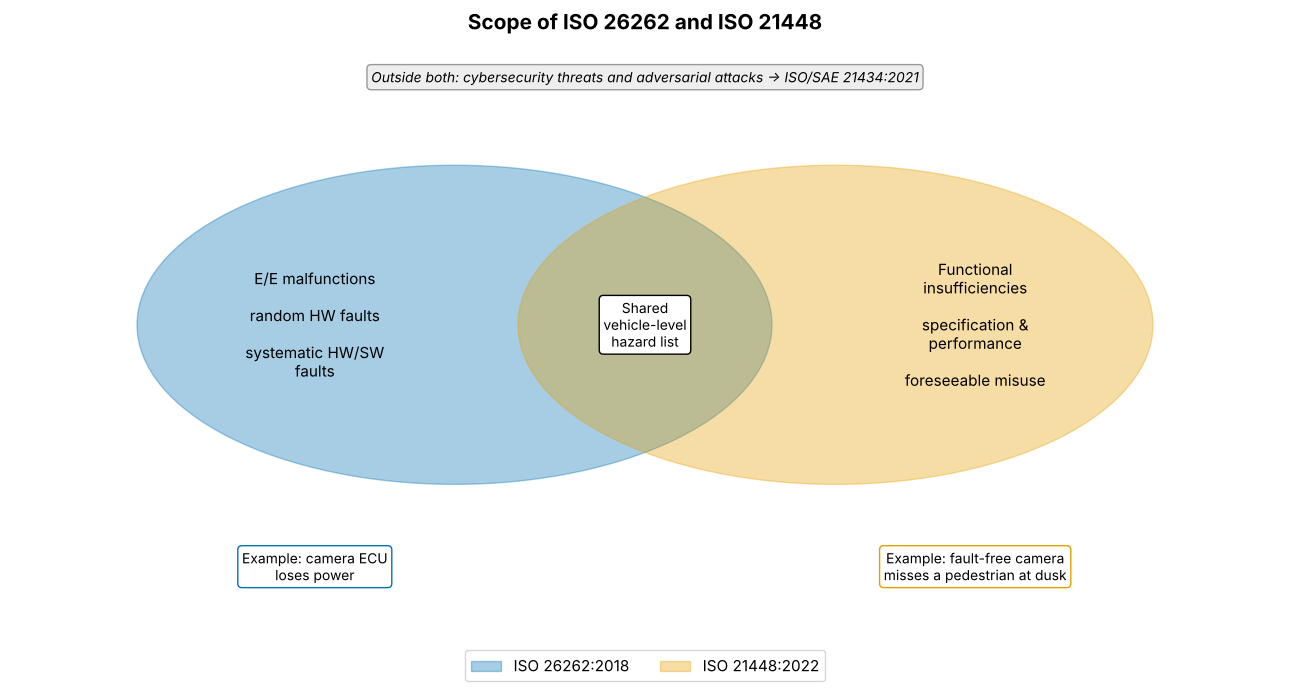

In [2]:
# Visualise the complementary scope of ISO 26262 and ISO 21448
def visualize_safety_scope():
    """Two overlapping scopes plus what lies outside both."""
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.add_patch(plt.Circle((0.35, 0.55), 0.25, color=OI['blue'], alpha=0.35, label='ISO 26262:2018'))
    ax.add_patch(plt.Circle((0.65, 0.55), 0.25, color=OI['orange'], alpha=0.35, label='ISO 21448:2022'))

    ax.text(0.24, 0.55, 'E/E malfunctions\n\nrandom HW faults\n\nsystematic HW/SW\nfaults',
            ha='center', va='center', fontsize=11)
    ax.text(0.76, 0.55, 'Functional\ninsufficiencies\n\nspecification &\nperformance\n\nforeseeable misuse',
            ha='center', va='center', fontsize=11)
    ax.text(0.5, 0.55, 'Shared\nvehicle-level\nhazard list', ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', edgecolor=OI['black']))

    ax.text(0.24, 0.15, 'Example: camera ECU\nloses power', ha='center', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', edgecolor=OI['blue']))
    ax.text(0.76, 0.15, 'Example: fault-free camera\nmisses a pedestrian at dusk', ha='center', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', edgecolor=OI['orange']))
    ax.text(0.5, 0.93, 'Outside both: cybersecurity threats and adversarial attacks → ISO/SAE 21434:2021',
            ha='center', fontsize=10, style='italic',
            bbox=dict(boxstyle='round', facecolor='#eeeeee', edgecolor=OI['grey']))

    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    ax.set_title('Scope of ISO 26262 and ISO 21448', fontsize=15, fontweight='bold')
    ax.legend(loc='lower center', ncol=2, fontsize=11, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(); plt.show()

visualize_safety_scope()

## 2. The SOTIF causal chain

ISO 21448:2022 (clause 4.2) describes how a SOTIF-related hazardous event comes about. In compact form:

```
Triggering condition        (in the scenario:  low sun, child partly hidden by a parked van)
   └─ activates ─► Functional insufficiency   (in the system:  detector recall low for occluded children)
        └─ causes ─► Output insufficiency      (missed or late detection)
             └─ propagates to ─► Hazardous behaviour   (no or late braking)
                  └─ in a scenario where the hazard can lead to harm, and without sufficient
                     controllability by the people involved ─► Harm
```

Three consequences for analysis:

1. **Triggering conditions describe the world**, not the system: weather, lighting, road users and their behaviour,
   infrastructure, driver behaviour (including misuse) and *external* disturbances of sensors (dirt, spray, sun in
   the field of view).
2. **Sensor and algorithm limitations are functional insufficiencies**, not triggering conditions. "Out-of-distribution
   input" or "camera dynamic range" belong in the insufficiency column.
3. **False positives and false negatives are output insufficiencies**; whether they matter depends on the resulting
   vehicle behaviour and the scenario.

In [3]:
# A small, structured causal-chain table (illustrative, for a camera-based pedestrian AEB)
chains = pd.DataFrame([
    {'Triggering condition (scenario)': 'Low sun in camera field of view',
     'Functional insufficiency (system)': 'Performance: limited camera dynamic range',
     'Output insufficiency': 'Pedestrian not detected',
     'Hazardous behaviour': 'No braking'},
    {'Triggering condition (scenario)': 'Child steps out between parked cars',
     'Functional insufficiency (system)': 'Specification: no requirement for emerging pedestrians at < 1.5 s TTC',
     'Output insufficiency': 'Late object confirmation',
     'Hazardous behaviour': 'Late braking'},
    {'Triggering condition (scenario)': 'Metal plate on the road (bridge joint)',
     'Functional insufficiency (system)': 'Performance: radar cannot separate drivable from non-drivable metal objects',
     'Output insufficiency': 'False positive obstacle',
     'Hazardous behaviour': 'Unintended emergency braking'},
    {'Triggering condition (scenario)': 'Driver relies on the system while reading a phone',
     'Functional insufficiency (system)': 'Specification: driver-monitoring warning too late (foreseeable misuse)',
     'Output insufficiency': 'Warning not perceived',
     'Hazardous behaviour': 'No driver intervention'},
])
display(chains)

# Items that belong to *other* standards — useful to keep a sharp boundary
boundary = pd.DataFrame([
    ('Camera ECU power supply failure', 'ISO 26262 (random hardware fault)'),
    ('Software bug in tracker memory handling', 'ISO 26262 (systematic software fault)'),
    ('Adversarial sticker on a stop sign', 'ISO/SAE 21434 (cybersecurity threat)'),
    ('LiDAR spoofing attack', 'ISO/SAE 21434 (cybersecurity threat)'),
    ('Detector misses a person in an unusual costume', 'ISO 21448 (performance insufficiency + triggering condition)'),
], columns=['Cause', 'Handled by'])
display(boundary)

# Text summary (derived from the tables)
counts = boundary['Handled by'].str.extract(r'^(.*?)\s*\(')[0].value_counts()
print("Text summary:", f"{len(chains)} SOTIF causal chains listed;",
      ", ".join(f"{k}: {v} boundary example(s)" for k, v in counts.items()))

,Triggering condition (scenario),Functional insufficiency (system),Output insufficiency,Hazardous behaviour
0,Low sun in camera field of view,Performance: limited camera dynamic range,Pedestrian not detected,No braking
1,Child steps out between parked cars,Specification: no requirement for emerging ped...,Late object confirmation,Late braking
2,Metal plate on the road (bridge joint),Performance: radar cannot separate drivable fr...,False positive obstacle,Unintended emergency braking
3,Driver relies on the system while reading a phone,Specification: driver-monitoring warning too l...,Warning not perceived,No driver intervention


,Cause,Handled by
0,Camera ECU power supply failure,ISO 26262 (random hardware fault)
1,Software bug in tracker memory handling,ISO 26262 (systematic software fault)
2,Adversarial sticker on a stop sign,ISO/SAE 21434 (cybersecurity threat)
3,LiDAR spoofing attack,ISO/SAE 21434 (cybersecurity threat)
4,Detector misses a person in an unusual costume,ISO 21448 (performance insufficiency + trigger...


Text summary: 4 SOTIF causal chains listed; ISO 26262: 2 boundary example(s), ISO/SAE 21434: 2 boundary example(s), ISO 21448: 1 boundary example(s)


## 3. Scenario categories: Areas 1–4

ISO 21448:2022 (clause 4.2.2) partitions the scenario space along two dimensions — **known / unknown** and
**hazardous / not hazardous** — into four **Areas**:

|  | **Known** | **Unknown** |
|---|---|---|
| **Not hazardous** | **Area 1** — known, not hazardous | **Area 4** — unknown, not hazardous |
| **Hazardous** | **Area 2** — known, hazardous | **Area 3** — unknown, hazardous |

Notes that students often get wrong:

- The standard uses **Areas 1–4**, not "S1–S4" (which would also collide with the ISO 26262 severity classes S0–S3).
  The 2022 edition speaks of *hazardous / not hazardous*; "safe / unsafe" is PAS-era wording.
- **Area 3 is unknown *hazardous*; Area 4 is unknown *not hazardous*.**
- Membership of the ODD does not separate the areas — Area 2 scenarios are usually inside the ODD.
- **Area 4 needs no SOTIF action**; such scenarios simply move to Area 1 when they become known.
- **The objective** is to evaluate Areas 2 and 3 and to show that the residual risk they cause meets the acceptance
  criteria: Area 2 shrinks through functional modification (→ Area 1), Area 3 shrinks through discovery (→ Area 2,
  then treated) and is bounded statistically.
- Adversarial scenarios are **not** an example of Area 3 — attacks are a cybersecurity matter (ISO/SAE 21434).

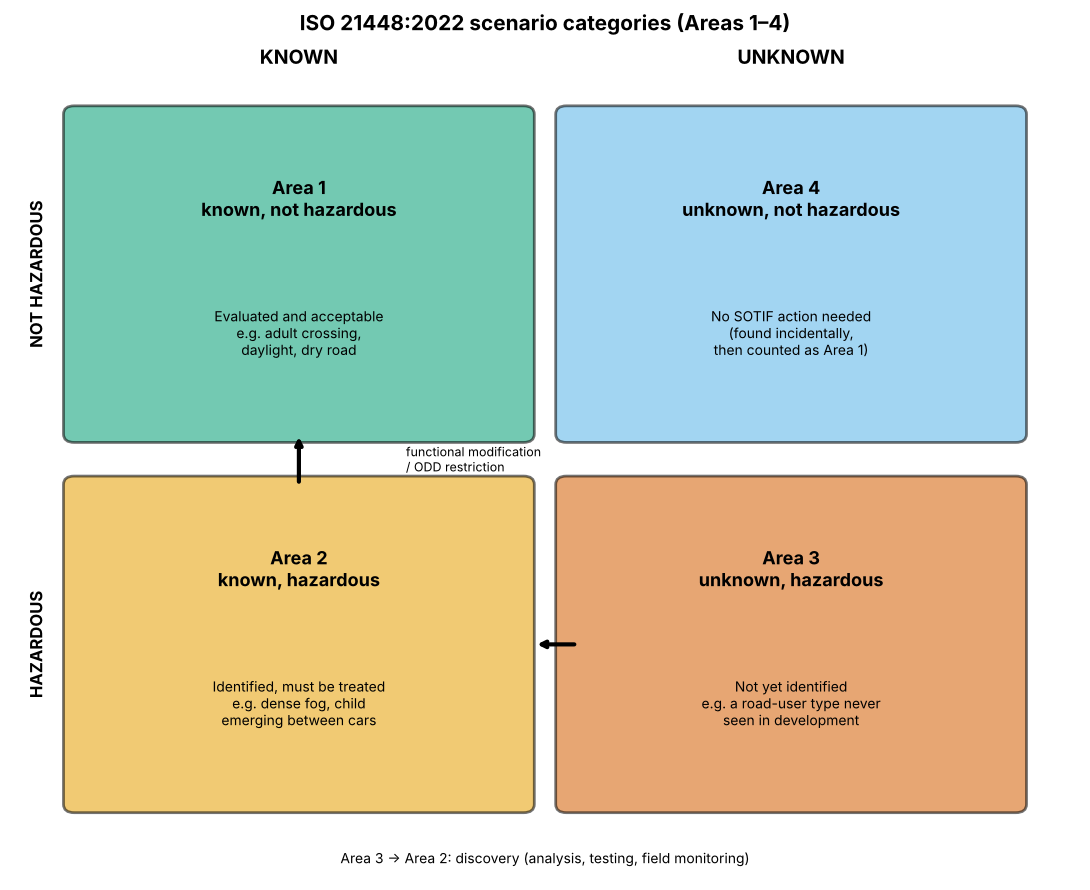

In [4]:
def visualize_sotif_areas():
    """The four ISO 21448 scenario areas and how activities move scenarios between them."""
    fig, ax = plt.subplots(figsize=(11, 9))
    areas = [
        {'name': 'Area 1\nknown, not hazardous', 'color': OI['green'], 'x': 0.27, 'y': 0.72,
         'desc': 'Evaluated and acceptable\ne.g. adult crossing,\ndaylight, dry road'},
        {'name': 'Area 2\nknown, hazardous', 'color': OI['orange'], 'x': 0.27, 'y': 0.28,
         'desc': 'Identified, must be treated\ne.g. dense fog, child\nemerging between cars'},
        {'name': 'Area 4\nunknown, not hazardous', 'color': OI['sky'], 'x': 0.73, 'y': 0.72,
         'desc': 'No SOTIF action needed\n(found incidentally,\nthen counted as Area 1)'},
        {'name': 'Area 3\nunknown, hazardous', 'color': OI['vermillion'], 'x': 0.73, 'y': 0.28,
         'desc': 'Not yet identified\ne.g. a road-user type never\nseen in development'},
    ]
    for a in areas:
        ax.add_patch(FancyBboxPatch((a['x'] - 0.21, a['y'] - 0.19), 0.42, 0.38, boxstyle='round,pad=0.01',
                                    facecolor=a['color'], edgecolor='black', linewidth=2, alpha=0.55))
        ax.text(a['x'], a['y'] + 0.09, a['name'], ha='center', va='center', fontsize=13, fontweight='bold')
        ax.text(a['x'], a['y'] - 0.07, a['desc'], ha='center', va='center', fontsize=10)

    ax.text(0.27, 0.97, 'KNOWN', ha='center', fontsize=14, fontweight='bold')
    ax.text(0.73, 0.97, 'UNKNOWN', ha='center', fontsize=14, fontweight='bold')
    ax.text(0.015, 0.72, 'NOT HAZARDOUS', rotation=90, va='center', fontsize=12, fontweight='bold')
    ax.text(0.015, 0.28, 'HAZARDOUS', rotation=90, va='center', fontsize=12, fontweight='bold')

    arrow = dict(arrowstyle='->', lw=3, color=OI['black'])
    ax.annotate('', xy=(0.49, 0.28), xytext=(0.53, 0.28), arrowprops=arrow)          # Area 3 -> Area 2
    ax.text(0.5, 0.02, 'Area 3 → Area 2: discovery (analysis, testing, field monitoring)', ha='center', fontsize=10)
    ax.annotate('', xy=(0.27, 0.53), xytext=(0.27, 0.47), arrowprops=arrow)          # Area 2 -> Area 1
    ax.text(0.37, 0.50, 'functional modification\n/ ODD restriction', ha='left', va='center', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0.0, 1); ax.axis('off')
    ax.set_title('ISO 21448:2022 scenario categories (Areas 1–4)', fontsize=15, fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_sotif_areas()

## 4. Triggering conditions in practice (illustrative)

A triggering-condition analysis lists conditions of the scenario, the functional insufficiency each one can
activate, and the evidence about the system's response. The numbers below show how such a table is used.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

"Detection rate" is a per-condition recall of a hypothetical camera pedestrian detector; "potential harm" is a
qualitative label for discussion, not an ISO 26262 severity class.

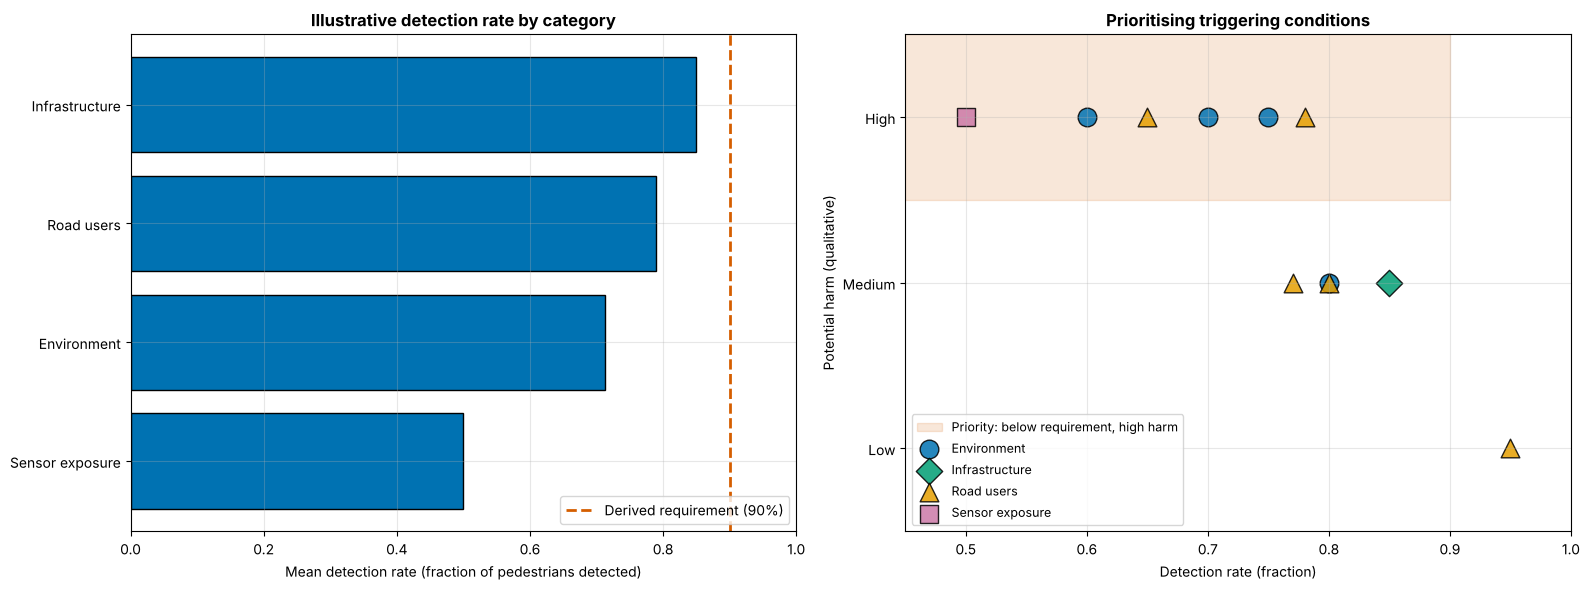

,Category,Triggering condition,Functional insufficiency,Detection rate,Potential harm,Meets requirement
4,Sensor exposure,Snow or ice on the sensor cover,Performance: no heating/cleaning specified,0.50,High,False
1,Environment,Dense fog,Performance: contrast below detector sensitivity,0.60,High,False
5,Road users,Pedestrian behind a parked vehicle,Performance: low recall under occlusion,0.65,High,False
3,Environment,Unlit rural road at night,Performance: low signal-to-noise ratio,0.70,High,False
0,Environment,Heavy rain (water film on windscreen),Performance: image blur reduces recall,0.75,High,False
7,Road users,Pedestrian carrying a large object,Performance: atypical silhouette,0.77,Medium,False
6,Road users,Child running out suddenly,Specification: reaction time budget too long,0.78,High,False
2,Environment,Low sun in camera field of view,Performance: limited dynamic range,0.80,Medium,False
8,Road users,Person in wheelchair,Performance: under-represented class in traini...,0.80,Medium,False
10,Infrastructure,Crowded intersection,Performance: crowding reduces instance separation,0.85,Medium,False


Text summary: 11 triggering conditions; 10 below the illustrative requirement; 6 of these with high potential harm: Heavy rain (water film on windscreen); Dense fog; Unlit rural road at night; Snow or ice on the sensor cover; Pedestrian behind a parked vehicle; Child running out suddenly


In [5]:
# Illustrative triggering-condition table (synthetic values)
tc_rows = [
    # category, triggering condition (scenario), functional insufficiency it may activate, detection rate, harm
    ('Environment', 'Heavy rain (water film on windscreen)', 'Performance: image blur reduces recall', 0.75, 'High'),
    ('Environment', 'Dense fog', 'Performance: contrast below detector sensitivity', 0.60, 'High'),
    ('Environment', 'Low sun in camera field of view', 'Performance: limited dynamic range', 0.80, 'Medium'),
    ('Environment', 'Unlit rural road at night', 'Performance: low signal-to-noise ratio', 0.70, 'High'),
    ('Sensor exposure', 'Snow or ice on the sensor cover', 'Performance: no heating/cleaning specified', 0.50, 'High'),
    ('Road users', 'Pedestrian behind a parked vehicle', 'Performance: low recall under occlusion', 0.65, 'High'),
    ('Road users', 'Child running out suddenly', 'Specification: reaction time budget too long', 0.78, 'High'),
    ('Road users', 'Pedestrian carrying a large object', 'Performance: atypical silhouette', 0.77, 'Medium'),
    ('Road users', 'Person in wheelchair', 'Performance: under-represented class in training data', 0.80, 'Medium'),
    ('Road users', 'Reflective clothing at night', 'None expected', 0.95, 'Low'),
    ('Infrastructure', 'Crowded intersection', 'Performance: crowding reduces instance separation', 0.85, 'Medium'),
]
df_tc = pd.DataFrame(tc_rows, columns=['Category', 'Triggering condition', 'Functional insufficiency',
                                       'Detection rate', 'Potential harm'])
REQUIRED_RATE = 0.90   # illustrative *derived* perception requirement (traced to an acceptance criterion, Section 6)
df_tc['Meets requirement'] = df_tc['Detection rate'] >= REQUIRED_RATE

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
cat_avg = df_tc.groupby('Category')['Detection rate'].mean().sort_values()
ax1.barh(cat_avg.index, cat_avg.values, color=OI['blue'], edgecolor='black')
ax1.axvline(REQUIRED_RATE, color=OI['vermillion'], ls='--', lw=2, label=f'Derived requirement ({REQUIRED_RATE:.0%})')
ax1.set_xlabel('Mean detection rate (fraction of pedestrians detected)')
ax1.set_title('Illustrative detection rate by category', fontweight='bold')
ax1.set_xlim(0, 1); ax1.legend(loc='lower right')

harm_map = {'Low': 1, 'Medium': 2, 'High': 3}
markers = {'Environment': 'o', 'Sensor exposure': 's', 'Road users': '^', 'Infrastructure': 'D'}
colors = {'Environment': OI['blue'], 'Sensor exposure': OI['purple'], 'Road users': OI['orange'], 'Infrastructure': OI['green']}
ax2.add_patch(plt.Rectangle((0.45, 2.5), REQUIRED_RATE - 0.45, 1.0, color=OI['vermillion'], alpha=0.15,
                            label='Priority: below requirement, high harm'))
for cat, sub in df_tc.groupby('Category'):
    ax2.scatter(sub['Detection rate'], sub['Potential harm'].map(harm_map), s=180, marker=markers[cat],
                color=colors[cat], edgecolor='black', label=cat, alpha=0.85)
ax2.set_yticks([1, 2, 3]); ax2.set_yticklabels(['Low', 'Medium', 'High'])
ax2.set_xlim(0.45, 1.0); ax2.set_ylim(0.5, 3.5)
ax2.set_xlabel('Detection rate (fraction)'); ax2.set_ylabel('Potential harm (qualitative)')
ax2.set_title('Prioritising triggering conditions', fontweight='bold')
ax2.legend(loc='lower left', fontsize=9)
plt.tight_layout(); plt.show()

display(df_tc.sort_values('Detection rate'))
prio = df_tc[(~df_tc['Meets requirement']) & (df_tc['Potential harm'] == 'High')]
print(f"Text summary: {len(df_tc)} triggering conditions; {(~df_tc['Meets requirement']).sum()} below the "
      f"illustrative requirement; {len(prio)} of these with high potential harm: "
      + "; ".join(prio['Triggering condition']))

## 5. The ISO 21448:2022 activity flow

The standard organises its activities as follows (clause numbers of ISO 21448:2022; titles paraphrased):

| Clause | Activity | Key output |
|---|---|---|
| 5 | **Specification and design** | Specification of the intended functionality, ODD, system architecture |
| 6 | **Identification and evaluation of hazards** (risk evaluation) | Hazards and hazardous behaviours; **acceptance criteria** for the residual risk |
| 7 | **Identification and evaluation of potential functional insufficiencies and potential triggering conditions** | List of insufficiencies, triggering conditions and foreseeable misuse; estimate of their acceptability |
| 8 | **Functional modifications addressing SOTIF-related risks** | Improved performance, restricted ODD, handover to driver, runtime monitors |
| 9 | **Definition of the verification and validation strategy** | V&V methods, **validation targets** derived from the acceptance criteria, with rationale |
| 10 | **Evaluation of known scenarios** | Evidence that residual risk from Area 2 is acceptable |
| 11 | **Evaluation of unknown scenarios** | Evidence that residual risk from Area 3 is acceptable with sufficient confidence |
| 12 | **Evaluation of the achievement of the SOTIF** | Release recommendation and SOTIF argument |
| 13 | **Operation phase activities** | Field monitoring; newly found triggering conditions feed back into clauses 5–8 |

The process is iterative: if the evaluation in clauses 10–12 shows that the residual risk is not acceptable, the
function is modified (clause 8) and evaluated again. Informative Annex C of the standard gives guidance on deriving
validation targets and on scenario parameterisation and sampling.

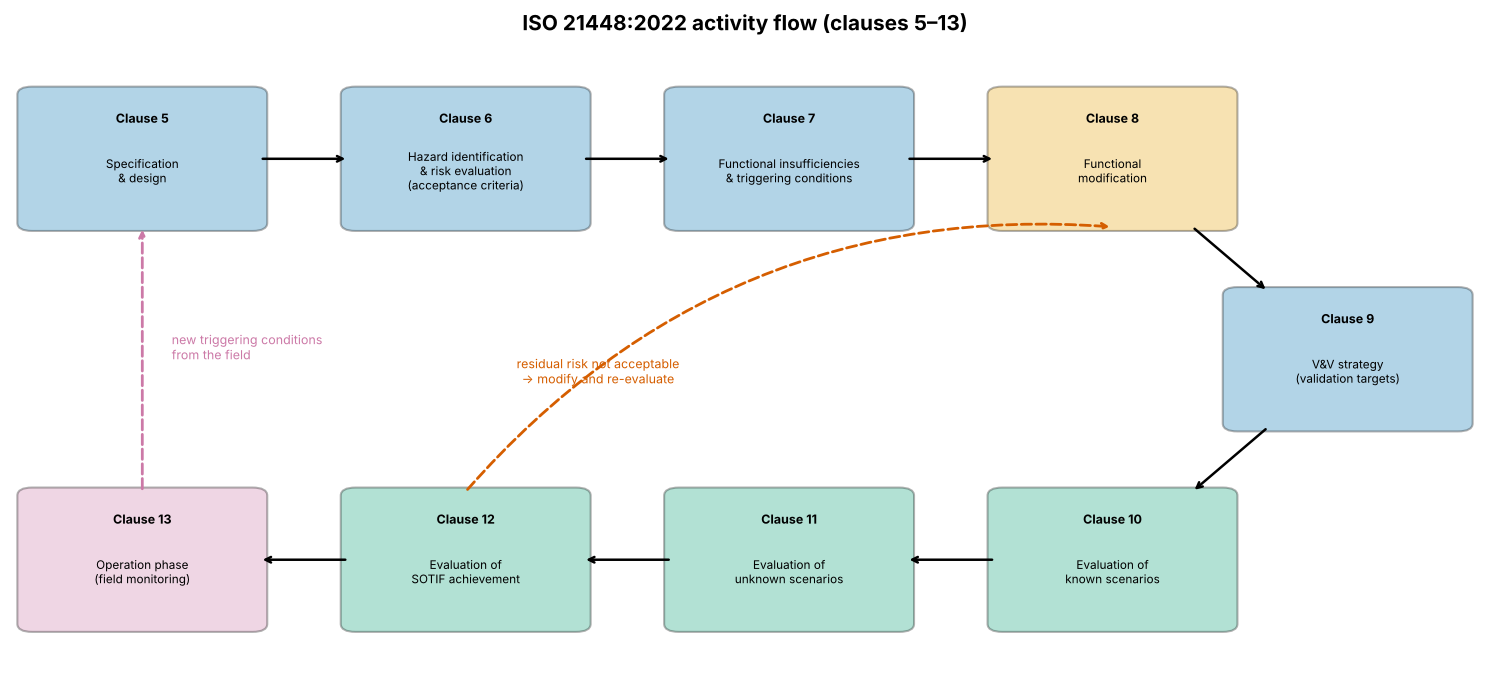

In [6]:
def visualize_sotif_flow():
    """ISO 21448:2022 activity flow (clauses 5–13) with the two iteration loops."""
    steps = [
        ('5', 'Specification\n& design'),
        ('6', 'Hazard identification\n& risk evaluation\n(acceptance criteria)'),
        ('7', 'Functional insufficiencies\n& triggering conditions'),
        ('8', 'Functional\nmodification'),
        ('9', 'V&V strategy\n(validation targets)'),
        ('10', 'Evaluation of\nknown scenarios'),
        ('11', 'Evaluation of\nunknown scenarios'),
        ('12', 'Evaluation of\nSOTIF achievement'),
        ('13', 'Operation phase\n(field monitoring)'),
    ]
    xs = [0.09, 0.31, 0.53, 0.75, 0.91, 0.75, 0.53, 0.31, 0.09]
    ys = [0.75, 0.75, 0.75, 0.75, 0.50, 0.25, 0.25, 0.25, 0.25]
    palette = [OI['blue']] * 3 + [OI['orange']] + [OI['blue']] + [OI['green']] * 3 + [OI['purple']]
    fig, ax = plt.subplots(figsize=(15, 7))
    for (num, label), x, y, c in zip(steps, xs, ys, palette):
        ax.add_patch(FancyBboxPatch((x - 0.075, y - 0.08), 0.15, 0.16, boxstyle='round,pad=0.01',
                                    facecolor=c, alpha=0.3, edgecolor='black', linewidth=1.5))
        ax.text(x, y + 0.045, f'Clause {num}', ha='center', fontsize=9, fontweight='bold')
        ax.text(x, y - 0.015, label, ha='center', va='center', fontsize=8.5)
    def edge(x, y, dx, dy):
        # point where the ray from the box centre in direction (dx, dy) leaves the box
        t = min(0.08 / abs(dx) if dx else np.inf, 0.085 / abs(dy) if dy else np.inf)
        return x + t * dx, y + t * dy
    for i in range(len(steps) - 1):
        dx, dy = xs[i + 1] - xs[i], ys[i + 1] - ys[i]
        start = edge(xs[i], ys[i], dx, dy)
        end = edge(xs[i + 1], ys[i + 1], -dx, -dy)
        ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', lw=1.8, color='black'))
    # Loop 1: residual risk not acceptable -> functional modification
    ax.annotate('', xy=(0.75, 0.665), xytext=(0.31, 0.335),
                arrowprops=dict(arrowstyle='->', lw=2, color=OI['vermillion'], ls='--',
                                connectionstyle='arc3,rad=-0.25'))
    ax.text(0.40, 0.47, 'residual risk not acceptable\n→ modify and re-evaluate', ha='center',
            fontsize=9, color=OI['vermillion'])
    # Loop 2: field findings -> back to specification
    ax.annotate('', xy=(0.09, 0.665), xytext=(0.09, 0.335),
                arrowprops=dict(arrowstyle='->', lw=2, color=OI['purple'], ls='--'))
    ax.text(0.11, 0.50, 'new triggering conditions\nfrom the field', ha='left', fontsize=9, color=OI['purple'])
    ax.set_xlim(0, 1); ax.set_ylim(0.1, 0.9); ax.axis('off')
    ax.set_title('ISO 21448:2022 activity flow (clauses 5–13)', fontsize=15, fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_sotif_flow()

## 6. Acceptance criteria and validation targets

ISO 21448 does not prescribe numbers. It requires the developer to **specify acceptance criteria** for the residual
risk (clause 6) with a rationale — for example by reference to regulations, to the performance of existing
functions or of careful human drivers, and to traffic statistics for the target market — and to **derive validation
targets** from them (clause 9, Annex C).

A common quantitative form: *the rate of a given hazardous behaviour shall not exceed $\lambda_{AC}$ per hour of
operation*. If $k$ hazardous events are observed in an exposure of $n$ hours, the one-sided upper confidence bound
on the rate (Poisson model, confidence $C$) is

$$\lambda_{U} = \frac{\chi^2_{C}\big(2(k+1)\big)}{2n}.$$

Requiring $\lambda_U \le \lambda_{AC}$ gives the **validation target** — the exposure needed:

$$n \;\ge\; \frac{\chi^2_{C}\big(2(k+1)\big)}{2\,\lambda_{AC}}, \qquad k=0:\; n \ge \frac{-\ln(1-C)}{\lambda_{AC}} \approx \frac{3}{\lambda_{AC}} \text{ for } C=95\,\%.$$

The same function is available as `avsafety.validation.miles_to_demonstrate` (see repo `avsafety/`); the exposure
unit can be hours, kilometres or relevant scenario encounters.

> **Illustrative data:** the acceptance criterion below is a teaching value, not a recommended target.

Confidence,90%,95%,99%
Events observed k,,,
0,"230,259","299,573","460,517"
1,"388,972","474,386","663,835"
2,"532,232","629,579","840,595"
3,"668,078","775,366","1,004,512"


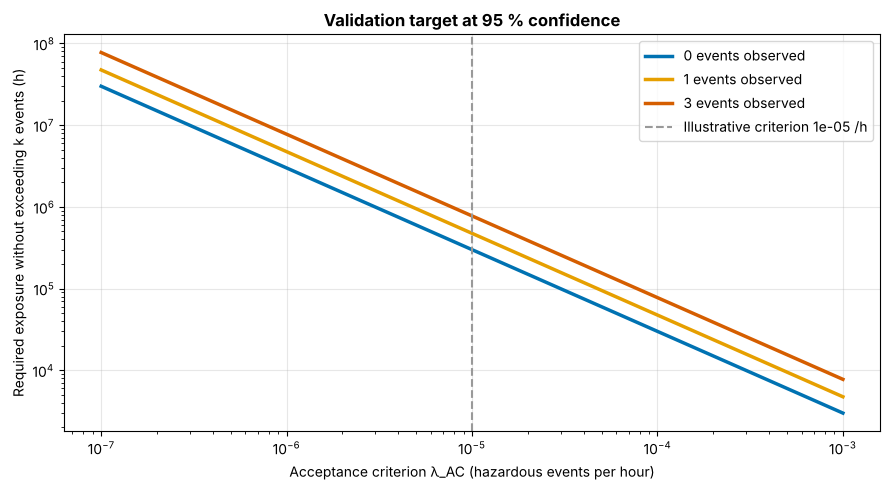

Text summary: to show λ < 1e-05/h at 95 % confidence with zero events requires 299,573 h; with 3 events it requires 775,366 h. At 60 km/h average this zero-event target is 17,974,394 km.


In [7]:
def exposure_to_demonstrate(rate, confidence=0.95, failures=0):
    """Exposure n such that `failures` observed events show rate < `rate` at the given confidence
    (one-sided Poisson/chi-square bound; identical to avsafety.validation.miles_to_demonstrate)."""
    return stats.chi2.ppf(confidence, 2 * (failures + 1)) / (2 * rate)

# Illustrative acceptance criterion for the hazardous behaviour "unintended emergency braking"
lambda_ac = 1e-5          # hazardous events per operating hour (teaching value)

rows = []
for C in (0.90, 0.95, 0.99):
    for k in (0, 1, 2, 3):
        rows.append({'Confidence': f'{C:.0%}', 'Events observed k': k,
                     'Validation target (h)': exposure_to_demonstrate(lambda_ac, C, k)})
targets = pd.DataFrame(rows).pivot(index='Events observed k', columns='Confidence', values='Validation target (h)')
display(targets.style.format('{:,.0f}'))

# Validation target as a function of the acceptance criterion
rates = np.logspace(-7, -3, 50)
fig, ax = plt.subplots(figsize=(9, 5))
for k, col in zip((0, 1, 3), (OI['blue'], OI['orange'], OI['vermillion'])):
    ax.loglog(rates, exposure_to_demonstrate(rates, 0.95, k), color=col, lw=2.5, label=f'{k} events observed')
ax.axvline(lambda_ac, color=OI['grey'], ls='--', label=f'Illustrative criterion {lambda_ac:g} /h')
ax.set_xlabel('Acceptance criterion λ_AC (hazardous events per hour)')
ax.set_ylabel('Required exposure without exceeding k events (h)')
ax.set_title('Validation target at 95 % confidence', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

n0 = exposure_to_demonstrate(lambda_ac, 0.95, 0)
print(f"Text summary: to show λ < {lambda_ac:g}/h at 95 % confidence with zero events requires "
      f"{n0:,.0f} h; with 3 events it requires {exposure_to_demonstrate(lambda_ac, 0.95, 3):,.0f} h. "
      f"At 60 km/h average this zero-event target is {n0*60:,.0f} km.")

Such targets are large. ISO 21448 therefore allows the argument to be built from several sources: exposure only to
the **relevant** subset of scenarios (for example only encounters with crossing pedestrians), simulation and proving
ground tests for known scenarios, and statistical arguments for unknown scenarios. Notebook
[04 · Simulation-based validation](04_simulation_based_validation.ipynb) shows how rare-event simulation reduces the
effort, and [06 · Statistical safety validation](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb)
develops the statistics further.

## 7. Worked example: SOTIF analysis of a pedestrian AEB

Each scenario below is **known** (it is in the table), so it can only be in Area 1 or Area 2. The area is
**computed** from the evaluation result against the illustrative derived requirement; the column `previous_area`
records where the scenario was before it was found — that history is what discovery activities produce.

> **Illustrative data:** performance values are synthetic, chosen for teaching; they are not measurements.

SOTIF register: Pedestrian detection with emergency braking
ODD: Pedestrian-relevant sub-scope of the AEB item (urban, ≤ 60 km/h): urban/suburban roads, daylight and dusk, dry or wet road



,id,description,performance,area,previous_area,discovered_by,triggering_condition,functional_insufficiency
0,SC-001,"Adult crossing, daylight, clear",0.98,Area 1,—,analysis,None identified,—
1,SC-002,Pedestrian in heavy rain,0.75,Area 2,—,analysis,Heavy rain (water film),Performance: camera recall in rain
2,SC-003,"Pedestrian in reflective vest, dusk",0.96,Area 1,Area 4,simulation,Low ambient light,—
3,SC-004,Dense fog at a crosswalk,0.60,Area 2,—,analysis,Dense fog,Performance: contrast below sensitivity
4,SC-005,Child on skateboard enters suddenly,0.70,Area 2,—,expert review,"Fast, small road user from kerb",Specification: max. pedestrian speed undefined...
5,SC-006,Pedestrian behind construction barrier,0.45,Area 2,Area 3,field monitoring,Occlusion at unexpected location,Performance: occlusion handling
6,SC-007,Pedestrian with large umbrella,0.92,Area 1,Area 4,simulation,Atypical silhouette,—
7,SC-008,Group of pedestrians at dusk,0.78,Area 2,—,analysis,Low light + clustering,Performance: instance separation


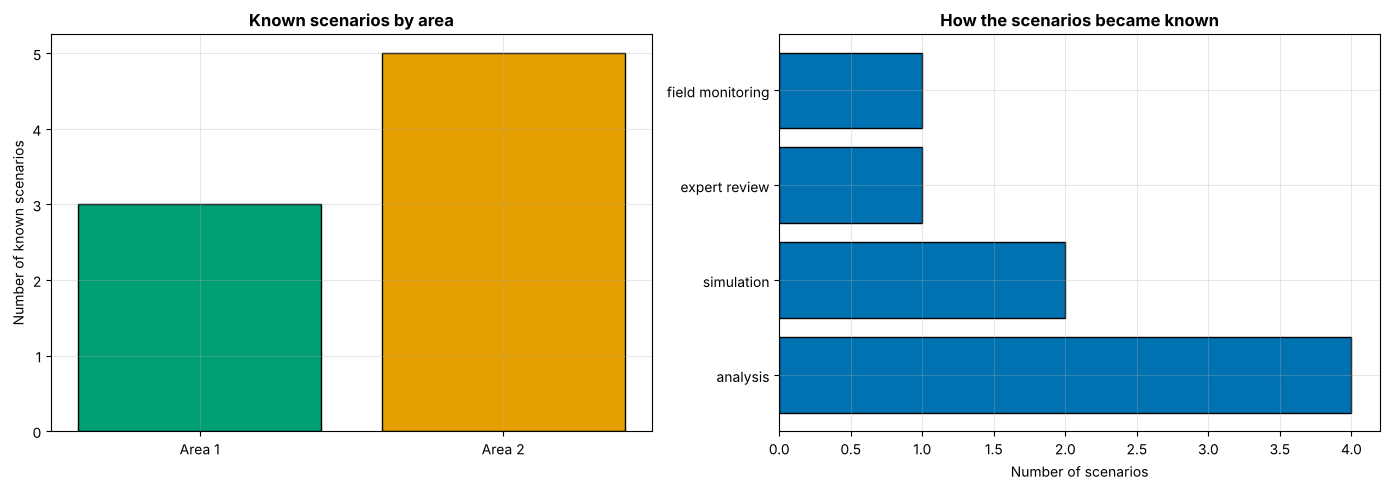

Text summary: 3 scenario(s) in Area 1, 5 in Area 2 (requirement 90%).
  SC-002 (75%): Radar fusion; speed reduction; warning
  SC-004 (60%): ODD restriction + ODD-exit detection
  SC-005 (70%): Specification update; training data
  SC-006 (45%): Detection improvement; speed limit in work zones
  SC-008 (78%): Improved low-light model; speed reduction
  1 scenario(s) moved from Area 3 to Area 2 via field monitoring — evidence that the discovery process works, and a prompt to look for similar ones.


In [8]:
class SOTIFAnalysis:
    """Minimal SOTIF scenario register: known scenarios are evaluated and placed in Area 1 or Area 2."""

    def __init__(self, system_name: str, odd: str, required_rate: float):
        self.system_name = system_name
        self.odd = odd
        self.required_rate = required_rate
        self.scenarios = []

    def add_scenario(self, scenario_id, description, performance, triggering_condition,
                     functional_insufficiency, measure, discovered_by, previous_area='—'):
        self.scenarios.append({
            'id': scenario_id, 'description': description, 'performance': performance,
            'triggering_condition': triggering_condition, 'functional_insufficiency': functional_insufficiency,
            'measure': measure, 'discovered_by': discovered_by, 'previous_area': previous_area})

    def analyze(self):
        df = pd.DataFrame(self.scenarios)
        # Known scenarios only: evaluation result decides between Area 1 and Area 2
        df['area'] = np.where(df['performance'] >= self.required_rate, 'Area 1', 'Area 2')
        return df

sotif = SOTIFAnalysis("Pedestrian detection with emergency braking",
                      "Pedestrian-relevant sub-scope of the AEB item (urban, ≤ 60 km/h): urban/suburban roads, "
                      "daylight and dusk, dry or wet road",
                      required_rate=REQUIRED_RATE)

sotif.add_scenario('SC-001', 'Adult crossing, daylight, clear', 0.98, 'None identified', '—',
                   'None needed', 'analysis')
sotif.add_scenario('SC-002', 'Pedestrian in heavy rain', 0.75, 'Heavy rain (water film)',
                   'Performance: camera recall in rain', 'Radar fusion; speed reduction; warning', 'analysis')
sotif.add_scenario('SC-003', 'Pedestrian in reflective vest, dusk', 0.96, 'Low ambient light',
                   '—', 'None needed', 'simulation', previous_area='Area 4')
sotif.add_scenario('SC-004', 'Dense fog at a crosswalk', 0.60, 'Dense fog',
                   'Performance: contrast below sensitivity', 'ODD restriction + ODD-exit detection', 'analysis')
sotif.add_scenario('SC-005', 'Child on skateboard enters suddenly', 0.70, 'Fast, small road user from kerb',
                   'Specification: max. pedestrian speed undefined; Performance: rare class',
                   'Specification update; training data', 'expert review')
sotif.add_scenario('SC-006', 'Pedestrian behind construction barrier', 0.45, 'Occlusion at unexpected location',
                   'Performance: occlusion handling', 'Detection improvement; speed limit in work zones',
                   'field monitoring', previous_area='Area 3')
sotif.add_scenario('SC-007', 'Pedestrian with large umbrella', 0.92, 'Atypical silhouette',
                   '—', 'None needed', 'simulation', previous_area='Area 4')
sotif.add_scenario('SC-008', 'Group of pedestrians at dusk', 0.78, 'Low light + clustering',
                   'Performance: instance separation', 'Improved low-light model; speed reduction', 'analysis')

df_sotif = sotif.analyze()
print(f"SOTIF register: {sotif.system_name}\nODD: {sotif.odd}\n")
display(df_sotif[['id', 'description', 'performance', 'area', 'previous_area', 'discovered_by',
                  'triggering_condition', 'functional_insufficiency']])

area_colors = {'Area 1': OI['green'], 'Area 2': OI['orange']}
counts = df_sotif['area'].value_counts().reindex(['Area 1', 'Area 2'], fill_value=0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(counts.index, counts.values, color=[area_colors[a] for a in counts.index], edgecolor='black')
ax1.set_ylabel('Number of known scenarios'); ax1.set_title('Known scenarios by area', fontweight='bold')
by_source = df_sotif['discovered_by'].value_counts()
ax2.barh(by_source.index, by_source.values, color=OI['blue'], edgecolor='black')
ax2.set_xlabel('Number of scenarios'); ax2.set_title('How the scenarios became known', fontweight='bold')
plt.tight_layout(); plt.show()

# Recommendations derived from the data
a2 = df_sotif[df_sotif['area'] == 'Area 2']
print(f"Text summary: {counts['Area 1']} scenario(s) in Area 1, {counts['Area 2']} in Area 2 "
      f"(requirement {REQUIRED_RATE:.0%}).")
for _, r in a2.iterrows():
    print(f"  {r['id']} ({r['performance']:.0%}): {r['measure']}")
moved = df_sotif[df_sotif['previous_area'] == 'Area 3']
if len(moved):
    print(f"  {len(moved)} scenario(s) moved from Area 3 to Area 2 via {', '.join(moved['discovered_by'].unique())} "
          "— evidence that the discovery process works, and a prompt to look for similar ones.")

## 8. Working with ISO 26262

| Aspect | ISO 26262:2018 | ISO 21448:2022 |
|---|---|---|
| **When** | All safety-related E/E systems in road vehicles | Functions whose safe behaviour depends on situational awareness from complex sensors and algorithms (ADAS and ADS), with or without ML |
| **Hazard analysis** | HARA → safety goals with ASIL | Shared vehicle-level hazard identification (clause 6) → acceptance criteria for residual risk |
| **Requirements** | Functional and technical safety requirements, ASIL-tagged | Specification improvements and performance requirements traced to acceptance criteria |
| **Verification** | Reviews, analyses, testing incl. fault injection | Verification of the function against known triggering conditions |
| **Validation** | Safety validation of safety goals at vehicle level | Evaluation of known (clause 10) and unknown (clause 11) hazardous scenarios against validation targets |
| **Lifecycle** | Concept → development → production, operation, service and decommissioning (Part 7) | Specification → V&V → release (clause 12) → operation-phase monitoring (clause 13) |

In practice both standards share one hazard list, one architecture and one safety case; Annex A of ISO 21448 discusses
the interaction. A cause is handled by one standard or the other depending on whether something *malfunctions*
(26262) or *works as specified but is insufficient* (21448).

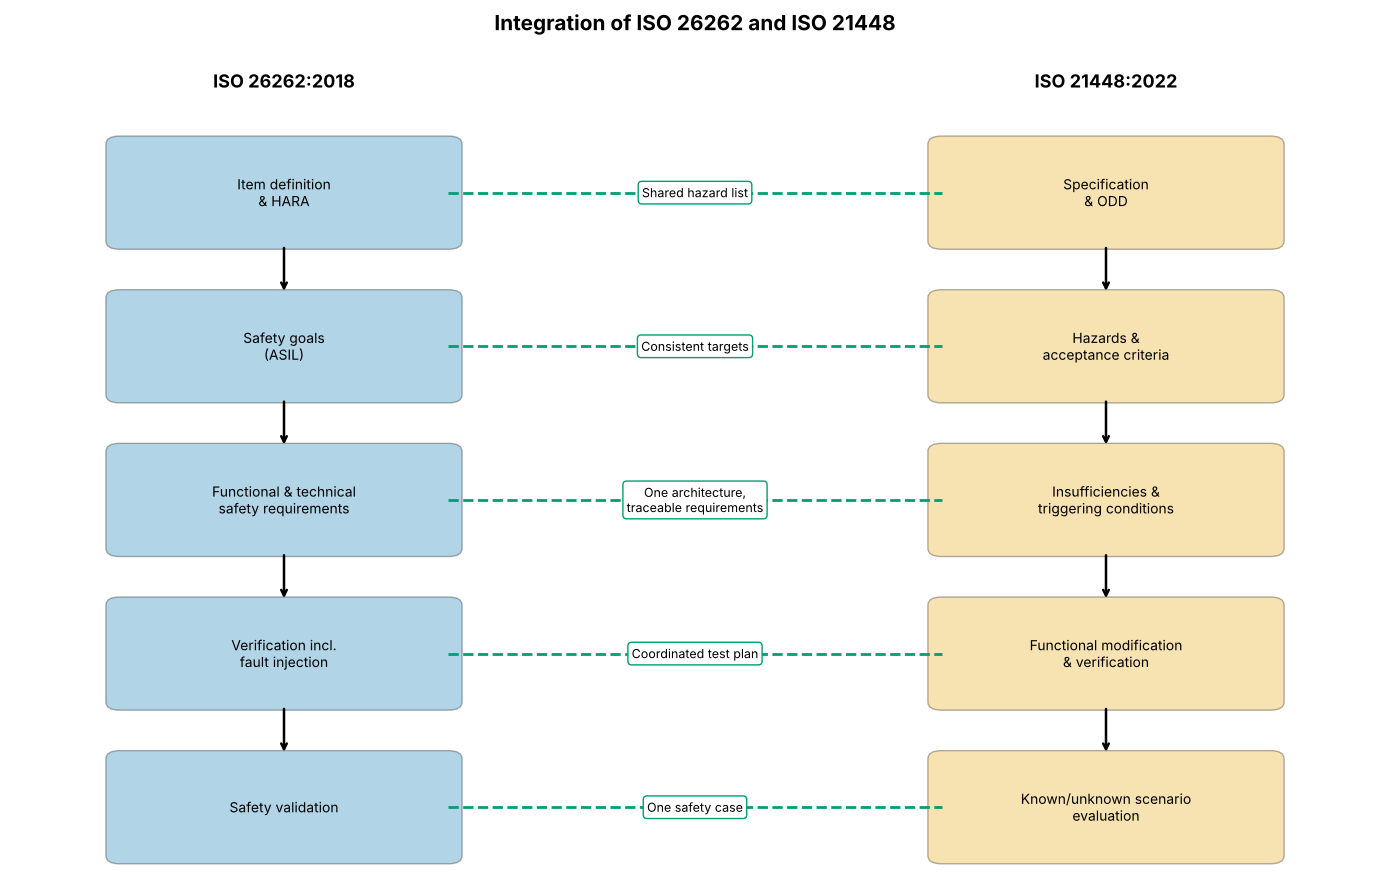

In [9]:
def visualize_integration():
    """Parallel ISO 26262 and ISO 21448 work products and their integration points."""
    fig, ax = plt.subplots(figsize=(14, 9))
    iso = ['Item definition\n& HARA', 'Safety goals\n(ASIL)', 'Functional & technical\nsafety requirements',
           'Verification incl.\nfault injection', 'Safety validation']
    sotif = ['Specification\n& ODD', 'Hazards &\nacceptance criteria', 'Insufficiencies &\ntriggering conditions',
             'Functional modification\n& verification', 'Known/unknown scenario\nevaluation']
    joint = ['Shared hazard list', 'Consistent targets', 'One architecture,\ntraceable requirements',
             'Coordinated test plan', 'One safety case']
    ys = [0.85, 0.66, 0.47, 0.28, 0.09]
    for x, steps, col in ((0.2, iso, OI['blue']), (0.8, sotif, OI['orange'])):
        for i, (y, s) in enumerate(zip(ys, steps)):
            ax.add_patch(FancyBboxPatch((x - 0.12, y - 0.06), 0.24, 0.12, boxstyle='round,pad=0.01',
                                        facecolor=col, alpha=0.3, edgecolor='black'))
            ax.text(x, y, s, ha='center', va='center', fontsize=10)
            if i < len(ys) - 1:
                ax.annotate('', xy=(x, ys[i + 1] + 0.065), xytext=(x, y - 0.065),
                            arrowprops=dict(arrowstyle='->', lw=1.8))
    for y, s in zip(ys, joint):
        ax.plot([0.32, 0.68], [y, y], ls='--', color=OI['green'], lw=2)
        ax.text(0.5, y, s, ha='center', va='center', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='white', edgecolor=OI['green']))
    ax.text(0.2, 0.98, 'ISO 26262:2018', ha='center', fontsize=13, fontweight='bold')
    ax.text(0.8, 0.98, 'ISO 21448:2022', ha='center', fontsize=13, fontweight='bold')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.axis('off')
    ax.set_title('Integration of ISO 26262 and ISO 21448', fontsize=15, fontweight='bold', pad=18)
    plt.tight_layout(); plt.show()

visualize_integration()

## 9. Exploring the unknown — what can and cannot be measured

A tempting metric is "scenario coverage = known scenarios / all scenarios". **It cannot be computed**: the
denominator includes Area 3 and Area 4, which are by definition unknown. What *can* be done:

1. **Measure coverage of a defined, discretised scenario space** (e.g. n-wise coverage of logical-scenario
   parameters) — see [Notebook 02](02_triggering_conditions_and_scenarios.ipynb). This says how well a *chosen*
   space was explored, not how much of reality it contains.
2. **Estimate the probability of meeting something new.** If field or test driving records which scenario classes
   occur, the Good–Turing estimator gives the probability that the next encounter belongs to a class never seen
   before: $\hat p_0 = N_1 / N$, where $N_1$ is the number of classes seen exactly once and $N$ the number of
   encounters (Hauer et al., 2019, use the related coupon-collector argument).
3. **Bound the residual risk statistically**, independently of whether scenarios are known (Section 6): a long
   exposure without hazardous behaviour bounds the rate of hazardous behaviour from *all* areas.

The simulation below has a long-tailed "true" distribution of scenario classes — which we know only because the data
are synthetic — so we can check how well the Good–Turing estimate tracks the true unseen probability mass.

> **Illustrative data:** synthetic scenario-class frequencies (Zipf-like), chosen for teaching.

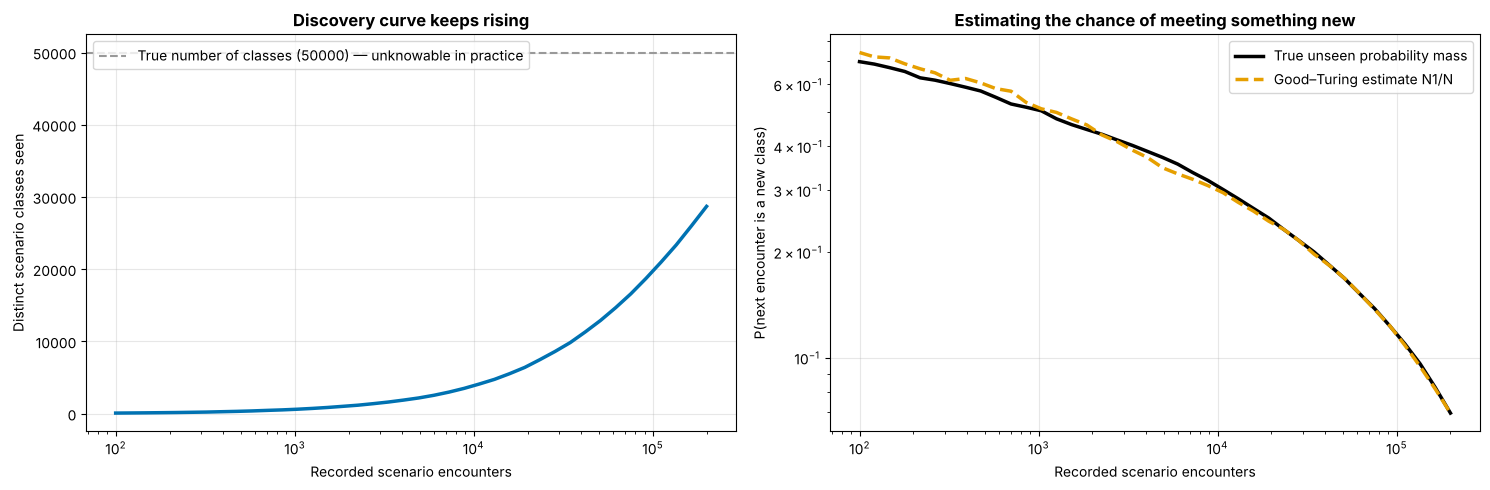

Text summary: after 200,000 encounters, 28697 of 50000 classes were seen ('coverage' 57%, computable only because the data are synthetic). Good–Turing estimates a 6.96% chance that the next encounter is new (true value 6.96%).


In [10]:
# Synthetic world: K scenario classes with long-tailed (Zipf-like) occurrence probabilities
K = 50_000
p_true = 1.0 / np.arange(1, K + 1) ** 1.0
p_true /= p_true.sum()

N_total = 200_000                                   # recorded scenario encounters
draws = rng.choice(K, size=N_total, p=p_true)

checkpoints = np.unique(np.logspace(2, np.log10(N_total), 40).astype(int))
records = []
for n in checkpoints:
    counts_n = np.bincount(draws[:n], minlength=K)
    seen = counts_n > 0
    records.append({'encounters': n,
                    'classes seen': seen.sum(),
                    'Good-Turing p0': (counts_n == 1).sum() / n,
                    'true unseen mass': p_true[~seen].sum()})
gt = pd.DataFrame(records)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.semilogx(gt['encounters'], gt['classes seen'], color=OI['blue'], lw=2.5)
ax1.axhline(K, color=OI['grey'], ls='--', label=f'True number of classes ({K}) — unknowable in practice')
ax1.set_xlabel('Recorded scenario encounters'); ax1.set_ylabel('Distinct scenario classes seen')
ax1.set_title('Discovery curve keeps rising', fontweight='bold'); ax1.legend(loc='upper left')

ax2.loglog(gt['encounters'], gt['true unseen mass'], color=OI['black'], lw=2.5, label='True unseen probability mass')
ax2.loglog(gt['encounters'], gt['Good-Turing p0'], color=OI['orange'], lw=2.5, ls='--', label='Good–Turing estimate N1/N')
ax2.set_xlabel('Recorded scenario encounters'); ax2.set_ylabel('P(next encounter is a new class)')
ax2.set_title('Estimating the chance of meeting something new', fontweight='bold'); ax2.legend()
plt.tight_layout(); plt.show()

last = gt.iloc[-1]
naive = last['classes seen'] / K
print(f"Text summary: after {int(last['encounters']):,} encounters, {int(last['classes seen'])} of {K} classes "
      f"were seen ('coverage' {naive:.0%}, computable only because the data are synthetic). "
      f"Good–Turing estimates a {last['Good-Turing p0']:.2%} chance that the next encounter is new "
      f"(true value {last['true unseen mass']:.2%}).")

Interpretation: a large share of the classes remains unseen, yet the chance of *meeting* one is much smaller than that
share suggests, and it can be estimated from the data alone. Neither number is a risk: an unseen class may well be harmless (Area 4). Risk
arguments therefore combine discovery with the exposure-based bound of Section 6 and with targeted search for hazardous
scenarios (simulation, falsification, field monitoring).

## In industry

**Work products.** ISO 21448 is applied as a set of linked work products: the **specification and design**
description of the function and its ODD (clause 5); the **hazard identification and risk evaluation** of the
intended functionality, usually shared with the ISO 26262 HARA (clause 6); the **identification and evaluation of
functional insufficiencies and triggering conditions** (clause 7); the **functional modifications** (clause 8); the
**V&V strategy** with acceptance criteria and validation targets (clause 9); the evaluation of known and unknown
scenarios (clauses 10–11); the **SOTIF release** argument (clause 12) and the **operation-phase** monitoring plan (clause 13).

**Who produces them.** A safety manager plans SOTIF together with functional safety; the function owner and system
architect write the specification; safety engineers run the hazard and triggering-condition analyses; perception,
planning and V&V teams provide evidence; an independent assessor reviews the release argument.

**What reviewers and assessors check.**

- [ ] Clear scope split: E/E faults (ISO 26262), attacks (ISO/SAE 21434), ML specifics (ISO/PAS 8800) referenced, not duplicated
- [ ] Acceptance criteria stated at vehicle level, with rationale (e.g. positive risk balance, field data of comparable systems)
- [ ] Validation targets derived from the criteria with an explicit confidence level and exposure
- [ ] Reasonably foreseeable misuse analysed, not only technical triggering conditions
- [ ] An argument for Area 3 (unknown hazardous scenarios) that goes beyond test coverage, plus an operation-phase loop

## Key takeaways

- ISO 21448:2022 addresses hazards from **functional insufficiencies** — insufficiencies of specification and
  performance insufficiencies — activated by **triggering conditions**; reasonably foreseeable misuse is in scope.
- E/E faults belong to **ISO 26262**, attacks to **ISO/SAE 21434**; ML-specific causes are elaborated in **ISO/PAS 8800**.
- The four scenario categories are **Areas 1–4**: Area 3 is *unknown hazardous*, Area 4 *unknown not hazardous*.
  SOTIF must show acceptable residual risk from Areas 2 and 3.
- The activity flow runs from specification (clause 5) to operation-phase monitoring (clause 13), with iteration
  through functional modification (clause 8).
- **Acceptance criteria** are vehicle-level residual-risk targets; **validation targets** are the exposures needed to
  demonstrate them with confidence.
- The share of unknown scenarios cannot be computed; discovery can be **estimated** and residual risk **bounded**.

## Self-assessment

1. What is the difference between functional safety (ISO 26262) and SOTIF (ISO 21448)?
2. Define *triggering condition* and *functional insufficiency*, and give one example of each for a camera-based system.
3. Name the four SOTIF areas. Which must be evaluated, and which needs no action?
4. An acceptance criterion is 10⁻⁶ hazardous events per hour. How many hours without such an event are needed at 95 % confidence?
5. Why is an adversarial patch attack not part of a SOTIF triggering-condition analysis?
6. Why can "coverage of unknown scenarios" not be computed, and what can be estimated instead?

<details>
<summary>Answers</summary>

1. ISO 26262 addresses hazards caused by malfunctions of E/E systems (random hardware faults, systematic
   hardware/software faults). ISO 21448 addresses hazards that arise when the system works as specified but the
   specification or its performance is insufficient, including reasonably foreseeable misuse.
2. A triggering condition is a specific condition of a scenario that activates a system reaction leading to
   hazardous behaviour, e.g. low sun in the camera's field of view. A functional insufficiency is an insufficiency of
   specification or a performance insufficiency, e.g. the camera's limited dynamic range.
3. Area 1 known/not hazardous, Area 2 known/hazardous, Area 3 unknown/hazardous, Area 4 unknown/not hazardous.
   Areas 2 and 3 must be evaluated; Area 4 needs no action.
4. $n = -\ln(0.05)/10^{-6} \approx 3.0 \times 10^{6}$ h.
5. Attacks are intentional manipulation, a cybersecurity threat excluded from ISO 21448 and handled by ISO/SAE 21434.
6. The total number of scenarios (including Areas 3 and 4) is unknown, so the denominator does not exist. One can
   measure coverage of a defined discretised space, estimate the probability of encountering a new scenario class
   (Good–Turing), and bound the rate of hazardous behaviour statistically.
</details>

## References

- ISO 21448:2022 *Road vehicles — Safety of the intended functionality* (1st ed.; replaces ISO/PAS 21448:2019). https://www.iso.org/standard/77490.html
- ISO 26262:2018 *Road vehicles — Functional safety* (Parts 1–12).
- ISO/SAE 21434:2021 *Road vehicles — Cybersecurity engineering*.
- ISO/PAS 8800:2024 *Road vehicles — Safety and artificial intelligence*. https://www.iso.org/standard/83303.html
- UL 4600 *Standard for Safety for the Evaluation of Autonomous Products*, 3rd ed. (2023).
- Kalra, N., Paddock, S. M. (2016). Driving to safety: How many miles of driving would it take to demonstrate autonomous vehicle reliability? *Transportation Research Part A* 94, 182–193. https://doi.org/10.1016/j.tra.2016.09.010
- Hauer, F., Schmidt, T., Holzmüller, B., Pretschner, A. (2019). Did We Test All Scenarios for Automated and Autonomous Driving Systems? *IEEE ITSC 2019*, 2950–2955. https://doi.org/10.1109/ITSC.2019.8917326
- Patel, M., Jung, R., Khatun, M. (2025). A Systematic Literature Review on Safety of the Intended Functionality for Automated Driving Systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030
- Patel, M., Jung, R. (2023). Simulation-Based Application of Safety of the Intended Functionality to Mitigate Foreseeable Misuse in Automated Driving Systems. SAE. https://doi.org/10.47953/sae-pp-00371
- Patel, M., Jung, R., Cakir, Y. (2023). Simulation-Based Testing of Foreseeable Misuse by the Driver Applicable for Highly Automated Driving. *LNNS*, Springer, 183–191. https://doi.org/10.1007/978-981-99-3043-2_15

## Further practice

For hands-on triggering-condition exercises (environmental degradation of perception), see the author's companion
repository *AI Perception Safety Workshop* (external): https://github.com/milinpatel07/AI-Perception-Safety-Workshop

---
**Navigation:** ← [Module 04 overview](README.md) · [Course overview](../README.md) · [next: Triggering conditions and scenarios](02_triggering_conditions_and_scenarios.ipynb) →